In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_auc_score, roc_curve)

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")   # 0 = malignant, 1 = benign

print("Shape:", X.shape)
print("Classes:", list(data.target_names))
X.head()

Shape: (569, 30)
Classes: [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Missing values:", X.isnull().sum().sum())
print("\nClass distribution:")
print(y.value_counts())
X.describe().T.head(10)

Missing values: 0

Class distribution:
target
1    357
0    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


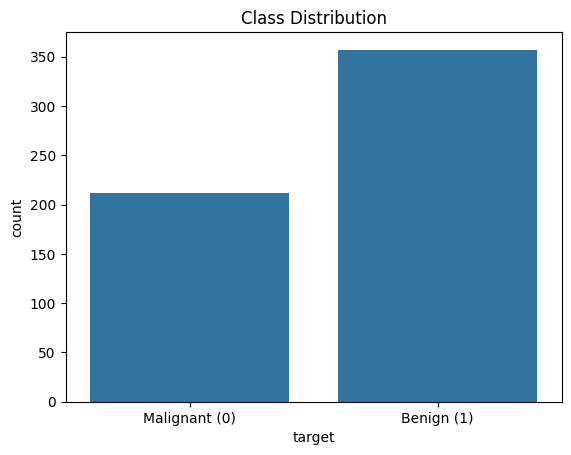

In [4]:
# Class balance plot
sns.countplot(x=y)
plt.xticks([0, 1], ["Malignant (0)", "Benign (1)"])
plt.title("Class Distribution")
plt.show()

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (455, 30)
Testing set : (114, 30)


In [6]:
dt = DecisionTreeClassifier(criterion="gini", random_state=42)
dt.fit(X_train, y_train)

y_pred = dt.predict(X_test)
y_prob = dt.predict_proba(X_test)[:, 1]

print("Tree depth      :", dt.get_depth())
print("Number of leaves:", dt.get_n_leaves())

Tree depth      : 7
Number of leaves: 19


In [7]:
print("Training accuracy:", round(dt.score(X_train, y_train), 4))
print("Testing accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision        :", round(precision_score(y_test, y_pred), 4))
print("Recall           :", round(recall_score(y_test, y_pred), 4))
print("F1-score         :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC          :", round(roc_auc_score(y_test, y_prob), 4))

Training accuracy: 1.0
Testing accuracy : 0.9123
Precision        : 0.9559
Recall           : 0.9028
F1-score         : 0.9286
ROC-AUC          : 0.9157


In [8]:
print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



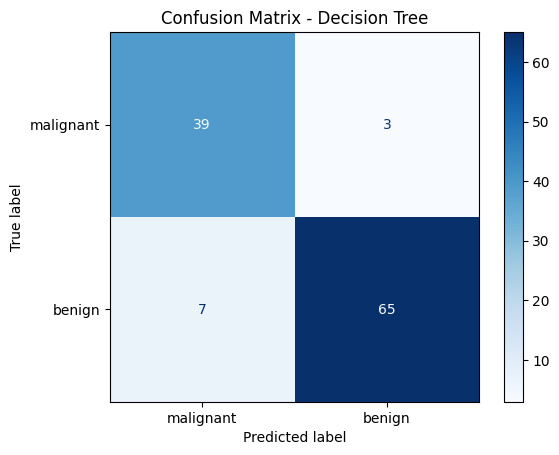

True Negatives : 39  (malignant correctly found)
False Positives: 3  (malignant predicted as benign)
False Negatives: 7  (benign predicted as malignant)
True Positives : 65  (benign correctly found)


In [9]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(cmap="Blues")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn}  (malignant correctly found)")
print(f"False Positives: {fp}  (malignant predicted as benign)")
print(f"False Negatives: {fn}  (benign predicted as malignant)")
print(f"True Positives : {tp}  (benign correctly found)")

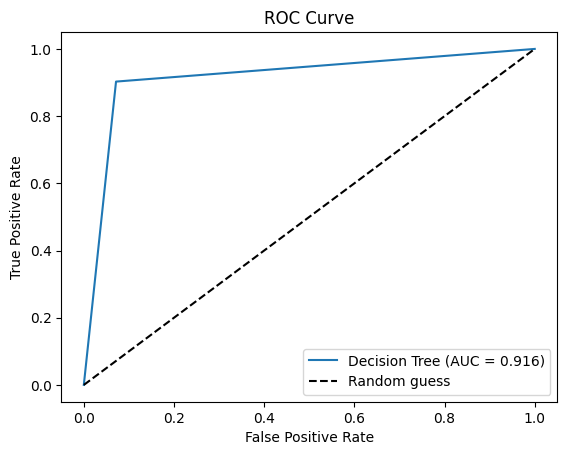

In [10]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

**Metric meanings**
- **Accuracy** = correct predictions / all predictions
- **Precision** = TP / (TP + FP): of all predicted positive, how many are truly positive
- **Recall** = TP / (TP + FN): of all actual positive, how many we found
- **F1-score** = harmonic mean of precision and recall
- **ROC-AUC** = ability to separate the classes (1.0 is perfect, 0.5 is random)

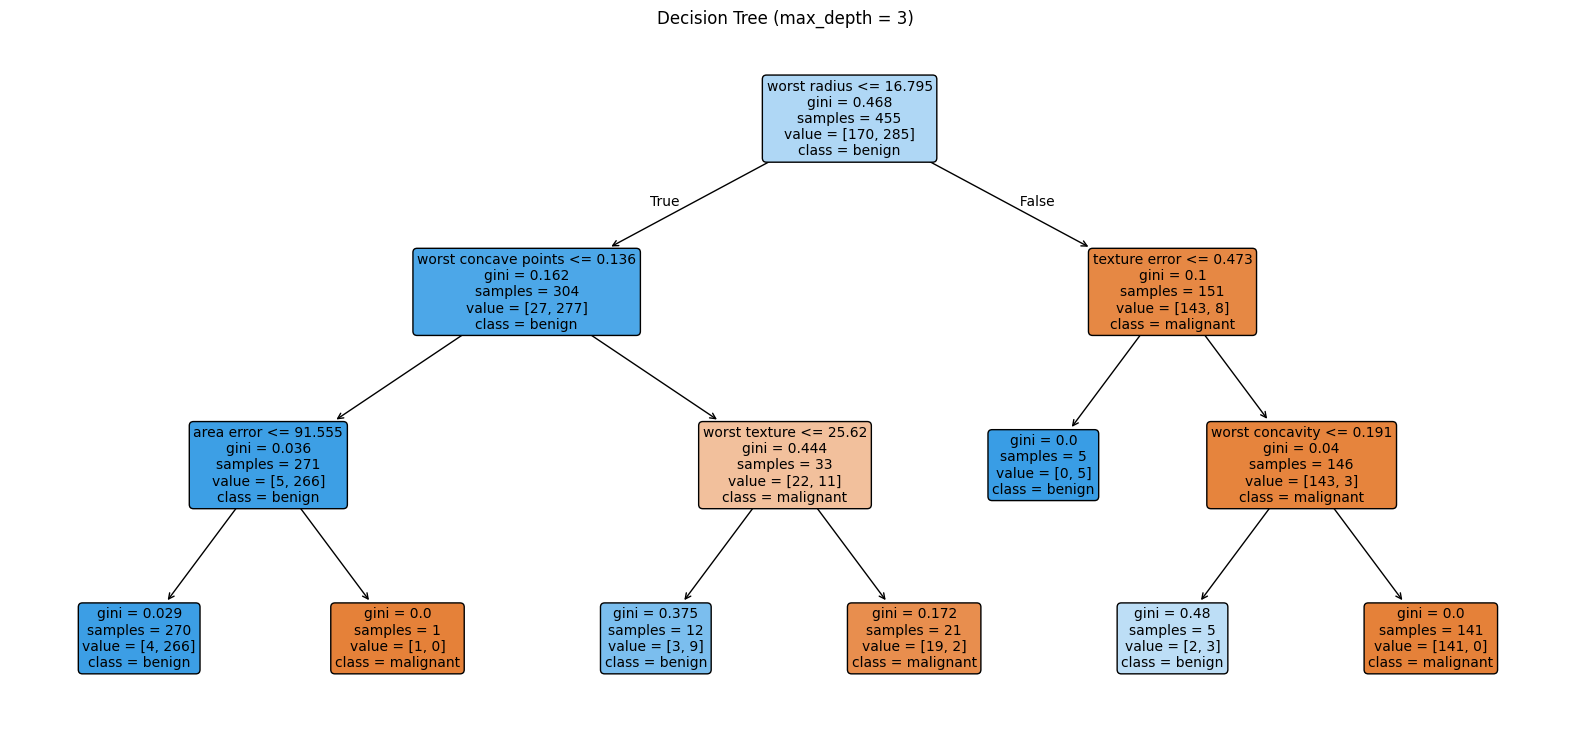

In [11]:
# Small tree (depth 3) so it is readable
dt_small = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(dt_small, feature_names=data.feature_names, class_names=data.target_names,
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree (max_depth = 3)")
plt.show()

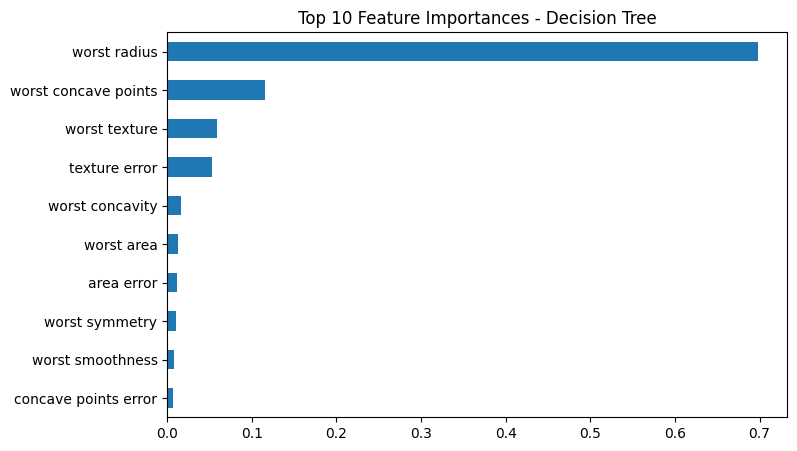

In [12]:
# Feature importance of the full tree
importances = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)

importances.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Feature Importances - Decision Tree")
plt.show()

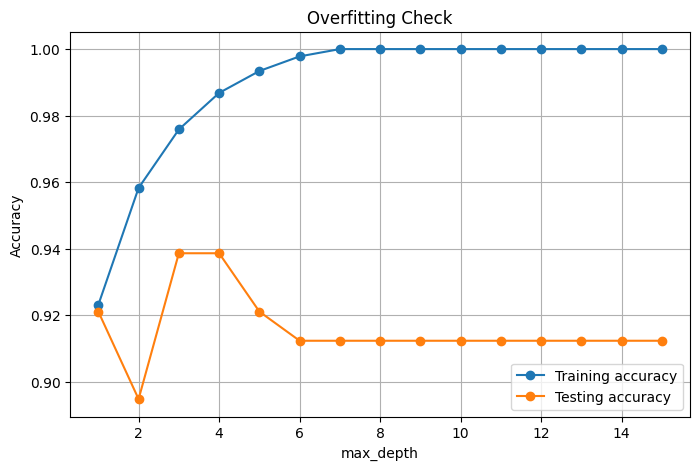

In [13]:
depths = range(1, 16)
train_acc, test_acc = [], []

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_acc, marker="o", label="Training accuracy")
plt.plot(depths, test_acc, marker="o", label="Testing accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting Check")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                    cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters :", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

In [ ]:
best_dt = grid.best_estimator_
y_pred_best = best_dt.predict(X_test)

print("Tuned Decision Tree - Test Results")
print("Accuracy :", round(accuracy_score(y_test, y_pred_best), 4))
print("Precision:", round(precision_score(y_test, y_pred_best), 4))
print("Recall   :", round(recall_score(y_test, y_pred_best), 4))
print("F1-score :", round(f1_score(y_test, y_pred_best), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, best_dt.predict_proba(X_test)[:, 1]), 4))

## Step 9: Compare with Random Forest
A Random Forest is an **ensemble of many decision trees**. It usually performs better and overfits less than a single tree.

In [ ]:
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

models = {"Decision Tree (default)": dt,
          "Decision Tree (tuned)": best_dt,
          "Random Forest": rf}

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "CV Accuracy (5-fold)": cross_val_score(m, X, y, cv=5).mean(),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

In [ ]:
results[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0.85, 1.0))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## Conclusion
- A Decision Tree splits the data using feature thresholds and is easy to interpret and visualize.
- The default (fully grown) tree gets 100% training accuracy but lower test accuracy, which shows **overfitting**.
- Limiting `max_depth` and tuning hyperparameters reduces overfitting.
- Accuracy alone can mislead, so precision, recall, F1, the confusion matrix and ROC-AUC give a fuller picture. In medical data, **recall** matters because missing a malignant case is costly.
- A Random Forest (many trees combined) gave the most stable and best performance.